# Step 8 — Ethereum: dipendenza tra utilizzo e priority fee

Valutiamo se modellare congiuntamente l'utilizzo, la mediana e la dispersione delle priority fee.
Le regressioni sono diagnostiche; un miglioramento predittivo non identifica un rapporto causale.

## Contesto e metodo

Fonte: [Zenodo 22094893](https://doi.org/10.5281/zenodo.22094893), preprocessing verificato nello step 1.
Fee in wei/gas nei log `log(1 + fee)`; P50/P90 ponderati per gas sulle transazioni incluse.
Stime sugli ultimi **30.000 blocchi contigui**: 20.000 training, 5.000 validation, 5.000 testing.
La validation documenta stabilità senza scegliere i modelli; il testing resta separato. Nessuna decimazione nelle stime.

### Assunzioni e allineamento

Il target è il blocco `n`; tutti i regressori sono del blocco chiuso `n−1`, disponibili alla decision origin.
Le associazioni contemporanee sono solo descrittive. Gli errori standard HAC usano 50 lag.
I test sono esplorativi senza correzione multipla; guardiamo anche coefficienti e MSE fuori campione.
Le regressioni lineari non rispettano automaticamente `0 ≤ X ≤ 2` o `D ≥ 0`: non sono simulatori utilizzabili senza vincoli.
Riferimento: [checklist, punto 8](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).

## Risultati osservati

Nel testing locale, aggiungere X ritardato riduce il MSE di log p50/p90 dell'**1,34%/0,74%**, dopo un peggioramento nella validation; i residui X–fee conservano correlazioni Pearson **−0,243/−0,201**.
La correlazione mediana–dispersione **−0,8925** ha anche una componente algebrica perché D = log p90 − log p50. I risultati motivano verifiche del kernel congiunto su altri periodi.
Le anomalie e i limiti di interpretazione sono in [findings.md](findings.md).

## Dati, finestra e lag osservabili

Carichiamo il campione completo per le distribuzioni e fissiamo una finestra contigua per le regressioni.
Costruiamo esplicitamente i lag prima di separare training, validation e testing.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file())
input_directory = root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((input_directory / "preprocessing_summary.json").read_text())
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
df = pd.read_parquet(input_directory / "ethereum_blocks_diagnostics.parquet")
assert len(df) == summary["rows"]
assert df["block_number"].diff().iloc[1:].eq(1).all()
output_directory = root / "outputs/notebook_diagnostics/ethereum/step8"
output_directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
labels = {
    "X": "Utilizzo X",
    "log_effective_priority_fee_per_gas_p50": "Log priority fee p50",
    "log_effective_priority_fee_per_gas_p90": "Log priority fee p90",
    "priority_fee_dispersion": "Dispersione log p90 − log p50",
}
print("Fonte: Zenodo 22094893; SHA-256:", summary["dataset_sha256"])
print("Blocchi:", df.block_number.iloc[0], "–", df.block_number.iloc[-1], "N =", len(df))

analysis = df.tail(30_001).copy()
assert len(analysis) == 30_001
series_columns = list(labels)
for column in series_columns + ["log_base_fee_per_gas"]:
    analysis["lag_" + column] = analysis[column].shift(1)
analysis = analysis.iloc[1:].reset_index(drop=True)
analysis["role"] = np.repeat(["training", "validation", "testing"], [20_000, 5_000, 5_000])
assert analysis["lag_X"].iloc[0] == df["X"].iloc[-30_001]
assert analysis.block_number.diff().iloc[1:].eq(1).all()
assert analysis.filter(like="lag_").notna().all().all()
train = analysis.role.eq("training")
validation = analysis.role.eq("validation")
test = analysis.role.eq("testing")
print(
    "Finestra UTC:", pd.to_datetime(analysis.timestamp.iloc[[0, -1]], unit="s", utc=True).tolist()
)
display(
    analysis.groupby("role", sort=False).agg(
        N=("block_number", "size"),
        primo_blocco=("block_number", "min"),
        ultimo_blocco=("block_number", "max"),
    )
)

Fonte: Zenodo 22094893; SHA-256: 4a8482552e3730ad68243a042eaa92b112450b36411f11a18947e9682d2e62e0
Blocchi: 23935694 – 25590229 N = 1654536
Finestra UTC: [Timestamp('2026-07-18 14:37:23+0000', tz='UTC'), Timestamp('2026-07-22 19:02:47+0000', tz='UTC')]


,N,primo_blocco,ultimo_blocco
role,,,
training,20000,25560230,25580229
validation,5000,25580230,25585229
testing,5000,25585230,25590229


## 8.1 — Priority fee correnti e utilizzo ritardato

Regrediamo log p50 e log p90 sui propri lag e sull'utilizzo del blocco precedente.
Misuriamo il contributo cross-lag con coefficienti HAC e confronto fuori campione con il solo lag proprio.

In [2]:
p50 = "log_effective_priority_fee_per_gas_p50"
p90 = "log_effective_priority_fee_per_gas_p90"
models = {}
coefficient_rows = []
forecast_rows = []


def fit_cross_model(target, cross, name):
    baseline_columns = ["lag_" + target]
    joint_columns = baseline_columns + ["lag_" + cross]
    baseline = sm.OLS(
        analysis.loc[train, target], sm.add_constant(analysis.loc[train, baseline_columns])
    ).fit()
    joint = sm.OLS(
        analysis.loc[train, target], sm.add_constant(analysis.loc[train, joint_columns])
    ).fit(cov_type="HAC", cov_kwds={"maxlags": 50})
    assert joint.nobs == baseline.nobs == train.sum()
    interval = joint.conf_int().loc["lag_" + cross]
    coefficient_rows.append(
        {
            "modello": name,
            "target": target,
            "cross_lag": cross,
            "coefficiente": joint.params["lag_" + cross],
            "HAC95_inferiore": interval.iloc[0],
            "HAC95_superiore": interval.iloc[1],
            "p_value_HAC": joint.pvalues["lag_" + cross],
        }
    )
    baseline_prediction = baseline.predict(
        sm.add_constant(analysis[baseline_columns], has_constant="add")
    )
    joint_prediction = joint.predict(sm.add_constant(analysis[joint_columns], has_constant="add"))
    for role, mask in [("validation", validation), ("testing", test)]:
        base_error = analysis.loc[mask, target] - baseline_prediction[mask]
        joint_error = analysis.loc[mask, target] - joint_prediction[mask]
        base_mse, joint_mse = np.mean(base_error**2), np.mean(joint_error**2)
        forecast_rows.append(
            {
                "modello": name,
                "role": role,
                "MSE_solo_proprio_lag": base_mse,
                "MSE_con_cross_lag": joint_mse,
                "riduzione_MSE_percento": 100 * (1 - joint_mse / base_mse),
            }
        )
    models[name] = {
        "fit": joint,
        "baseline_prediction": baseline_prediction,
        "prediction": joint_prediction,
        "residual": analysis[target] - joint_prediction,
    }


for target, name in [(p50, "p50_da_X"), (p90, "p90_da_X")]:
    fit_cross_model(target, "X", name)
display(pd.DataFrame(coefficient_rows))
display(pd.DataFrame(forecast_rows))

,modello,target,cross_lag,coefficiente,HAC95_inferiore,HAC95_superiore,p_value_HAC
0,p50_da_X,log_effective_priority_fee_per_gas_p50,X,0.418370,0.322038,0.514702,1.707514e-17
1,p90_da_X,log_effective_priority_fee_per_gas_p90,X,0.406615,0.334281,0.478949,3.142388e-28


,modello,role,MSE_solo_proprio_lag,MSE_con_cross_lag,riduzione_MSE_percento
0,p50_da_X,validation,3.715606,3.743393,-0.747837
1,p50_da_X,testing,5.274676,5.204197,1.336184
2,p90_da_X,validation,1.192115,1.212730,-1.729300
3,p90_da_X,testing,1.219539,1.210457,0.744732


## 8.2 — Contributo dell'utilizzo ritardato alle priority fee

Isoliamo coefficiente, intervallo HAC e guadagno predittivo del lag di utilizzo.
Un p-value basso descrive evidenza condizionata al modello, non causalità o utilità economica certa.

In [3]:
display(
    pd.DataFrame(coefficient_rows)[
        ["target", "coefficiente", "HAC95_inferiore", "HAC95_superiore", "p_value_HAC"]
    ]
)
display(pd.DataFrame(forecast_rows).query("role == 'testing'"))

,target,coefficiente,HAC95_inferiore,HAC95_superiore,p_value_HAC
0,log_effective_priority_fee_per_gas_p50,0.418370,0.322038,0.514702,1.707514e-17
1,log_effective_priority_fee_per_gas_p90,0.406615,0.334281,0.478949,3.142388e-28


,modello,role,MSE_solo_proprio_lag,MSE_con_cross_lag,riduzione_MSE_percento
1,p50_da_X,testing,5.274676,5.204197,1.336184
3,p90_da_X,testing,1.219539,1.210457,0.744732


## 8.3 — Utilizzo corrente e priority fee ritardate

Invertiamo la direzione predittiva: spieghiamo l'utilizzo con il proprio lag e con p50 oppure p90 ritardato.
Manteniamo lo stesso campione e controlliamo anche eventuali previsioni fuori dal supporto fisico.

In [4]:
for cross, name in [(p50, "X_da_p50"), (p90, "X_da_p90")]:
    fit_cross_model("X", cross, name)
coefficient_report = pd.DataFrame(coefficient_rows)
forecast_report = pd.DataFrame(forecast_rows)
display(coefficient_report.tail(2))
display(forecast_report.tail(4))
for name in ["X_da_p50", "X_da_p90"]:
    predicted = models[name]["prediction"][test]
    print(
        name, "previsioni X fuori [0,2] nel test:", int(((predicted < 0) | (predicted > 2)).sum())
    )
coefficient_report.to_csv(output_directory / "cross_lag_coefficients.csv", index=False)
forecast_report.to_csv(output_directory / "cross_lag_forecasts.csv", index=False)

,modello,target,cross_lag,coefficiente,HAC95_inferiore,HAC95_superiore,p_value_HAC
2,X_da_p50,X,log_effective_priority_fee_per_gas_p50,0.006308,0.001941,0.010675,0.004636
3,X_da_p90,X,log_effective_priority_fee_per_gas_p90,-0.010026,-0.015936,-0.004115,0.000886


,modello,role,MSE_solo_proprio_lag,MSE_con_cross_lag,riduzione_MSE_percento
4,X_da_p50,validation,0.154955,0.155494,-0.347489
5,X_da_p50,testing,0.161605,0.162225,-0.383610
6,X_da_p90,validation,0.154955,0.154694,0.168768
7,X_da_p90,testing,0.161605,0.161368,0.146746


X_da_p50 previsioni X fuori [0,2] nel test: 0
X_da_p90 previsioni X fuori [0,2] nel test: 0


## 8.4 — Contributo delle priority fee ritardate all'utilizzo

Isoliamo i coefficienti dei lag di p50 e p90 nelle regressioni dell'utilizzo.
Affianchiamo gli intervalli HAC al risultato nel testing per distinguere significatività e previsione.

In [5]:
display(coefficient_report[coefficient_report.target.eq("X")])
display(forecast_report.query("role == 'testing' and modello in ['X_da_p50', 'X_da_p90']"))

,modello,target,cross_lag,coefficiente,HAC95_inferiore,HAC95_superiore,p_value_HAC
2,X_da_p50,X,log_effective_priority_fee_per_gas_p50,0.006308,0.001941,0.010675,0.004636
3,X_da_p90,X,log_effective_priority_fee_per_gas_p90,-0.010026,-0.015936,-0.004115,0.000886


,modello,role,MSE_solo_proprio_lag,MSE_con_cross_lag,riduzione_MSE_percento
5,X_da_p50,testing,0.161605,0.162225,-0.383610
7,X_da_p90,testing,0.161605,0.161368,0.146746


## 8.5 — Correlazione delle innovazioni condizionate

Confrontiamo Pearson e Spearman tra residui dei modelli delle due variabili nel testing.
Ripetiamo il confronto quando il blocco precedente è congestionato, condizione osservabile alla decisione.

,fee,campione,N,Pearson,Spearman
0,p50,testing,5000,-0.243436,-0.293928
1,p50,testing con X_precedente >= 1.8,256,-0.337246,-0.361680
2,p90,testing,5000,-0.200808,-0.274421
3,p90,testing con X_precedente >= 1.8,256,-0.303999,-0.394181


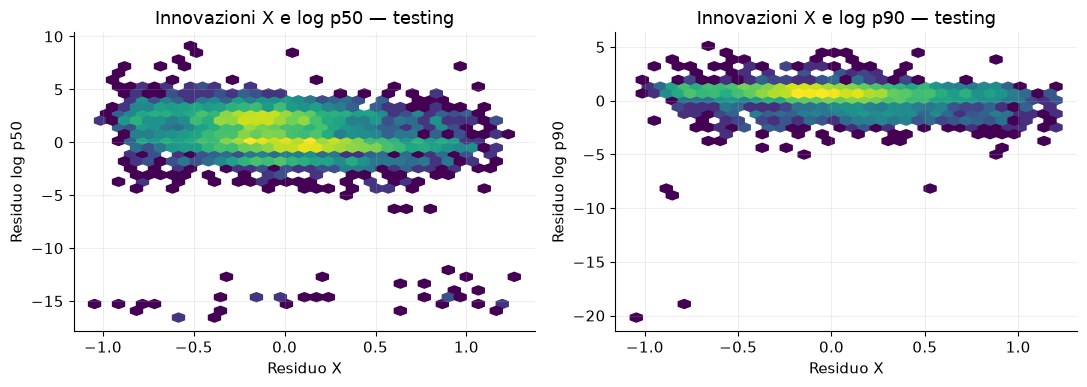

In [6]:
residual_correlation_rows = []
for fee, x_model, fee_model in [("p50", "X_da_p50", "p50_da_X"), ("p90", "X_da_p90", "p90_da_X")]:
    for period, mask in [
        ("testing", test),
        ("testing con X_precedente >= 1.8", test & analysis.lag_X.ge(1.8)),
    ]:
        pair = pd.DataFrame(
            {"X": models[x_model]["residual"][mask], fee: models[fee_model]["residual"][mask]}
        )
        residual_correlation_rows.append(
            {
                "fee": fee,
                "campione": period,
                "N": len(pair),
                "Pearson": pair.corr(method="pearson").iloc[0, 1],
                "Spearman": pair.corr(method="spearman").iloc[0, 1],
            }
        )
residual_correlation_report = pd.DataFrame(residual_correlation_rows)
display(residual_correlation_report)
residual_correlation_report.to_csv(output_directory / "residual_dependence.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fee, x_model, fee_model in zip(
    axes, ["p50", "p90"], ["X_da_p50", "X_da_p90"], ["p50_da_X", "p90_da_X"], strict=True
):
    ax.hexbin(
        models[x_model]["residual"][test],
        models[fee_model]["residual"][test],
        gridsize=35,
        mincnt=1,
        bins="log",
    )
    ax.set(
        title=f"Innovazioni X e log {fee} — testing",
        xlabel="Residuo X",
        ylabel=f"Residuo log {fee}",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## 8.6 — Dipendenza non lineare e alta congestione

Aggiungiamo il quadrato dell'utilizzo ritardato e confrontiamo le previsioni con la relazione lineare.
Il termine quadratico è fissato prima del test; la sua significatività non prova causalità né un modello ottimale.

In [7]:
analysis["lag_X_squared"] = analysis.lag_X**2
nonlinear_rows = []
for target, name in [(p50, "p50_da_X"), (p90, "p90_da_X")]:
    columns = ["lag_" + target, "lag_X", "lag_X_squared"]
    fitted = sm.OLS(analysis.loc[train, target], sm.add_constant(analysis.loc[train, columns])).fit(
        cov_type="HAC", cov_kwds={"maxlags": 50}
    )
    prediction = fitted.predict(sm.add_constant(analysis[columns], has_constant="add"))
    for period, mask in [
        ("testing", test),
        ("testing congestionato", test & analysis.lag_X.ge(1.8)),
    ]:
        mse_linear = np.mean(models[name]["residual"][mask] ** 2)
        mse_quadratic = np.mean((analysis.loc[mask, target] - prediction[mask]) ** 2)
        nonlinear_rows.append(
            {
                "target": target,
                "campione": period,
                "N": int(mask.sum()),
                "coefficiente_X2": fitted.params["lag_X_squared"],
                "p_value_HAC_X2": fitted.pvalues["lag_X_squared"],
                "MSE_lineare": mse_linear,
                "MSE_quadratico": mse_quadratic,
                "riduzione_MSE_percento": 100 * (1 - mse_quadratic / mse_linear),
            }
        )
nonlinear_report = pd.DataFrame(nonlinear_rows)
display(nonlinear_report)
nonlinear_report.to_csv(output_directory / "nonlinear_dependence.csv", index=False)

,target,campione,N,coefficiente_X2,p_value_HAC_X2,MSE_lineare,MSE_quadratico,riduzione_MSE_percento
0,log_effective_priority_fee_per_gas_p50,testing,5000,-0.632339,7.773400e-16,5.204197,5.110783,1.794975
1,log_effective_priority_fee_per_gas_p50,testing congestionato,256,-0.632339,7.773400e-16,12.097443,11.980832,0.963933
2,log_effective_priority_fee_per_gas_p90,testing,5000,-0.388389,1.914450e-13,1.210457,1.196620,1.143091
3,log_effective_priority_fee_per_gas_p90,testing congestionato,256,-0.388389,1.914450e-13,1.481786,1.491142,-0.631434


## 8.7 — Distribuzioni condizionate per fasce di utilizzo

Sul campione completo confrontiamo quantili e medie delle fee nelle fasce di utilizzo corrente.
È un'associazione contemporanea descrittiva: l'utilizzo del blocco futuro non entra nei regressori predittivi.

,fascia_X_corrente,variabile,N_blocchi,media,q10_tra_blocchi,q50_tra_blocchi,q90_tra_blocchi,q99_tra_blocchi
0,"(-0.001, 0.5]",priority_fee_p50_gwei,189759,1.16833,0.00100,0.03508,0.97154,9.20270
1,"(-0.001, 0.5]",priority_fee_p90_gwei,189759,5.25439,0.50000,1.97917,4.19342,64.72190
2,"(-0.001, 0.5]",priority_fee_dispersion,189759,4.35965,1.33305,3.67918,6.78495,21.41641
3,"(0.5, 1.0]",priority_fee_p50_gwei,720881,0.16857,0.00121,0.01470,0.25864,1.50000
4,"(0.5, 1.0]",priority_fee_p90_gwei,720881,2.14305,0.50000,1.50000,2.10000,14.44956
5,"(0.5, 1.0]",priority_fee_dispersion,720881,4.50077,2.11403,4.36879,6.57432,16.62892
6,"(1.0, 1.5]",priority_fee_p50_gwei,483138,0.09162,0.00100,0.00903,0.17222,1.40568
7,"(1.0, 1.5]",priority_fee_p90_gwei,483138,1.57619,0.20000,1.00000,2.00000,8.96129
8,"(1.0, 1.5]",priority_fee_dispersion,483138,4.78992,2.30259,4.60517,6.90775,17.08635
9,"(1.5, 1.8]",priority_fee_p50_gwei,119863,0.05256,0.00014,0.00449,0.09256,1.00000


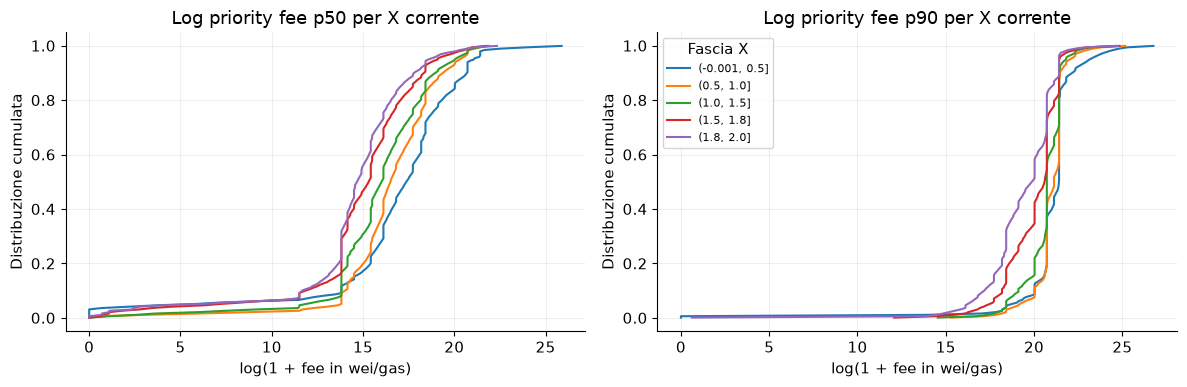

In [8]:
bands = pd.cut(df.X, [0, 0.5, 1, 1.5, 1.8, 2], include_lowest=True)
conditional_rows = []
for band, frame in df.groupby(bands, observed=True):
    for column in ["priority_fee_p50_gwei", "priority_fee_p90_gwei", "priority_fee_dispersion"]:
        values = frame[column]
        conditional_rows.append(
            {
                "fascia_X_corrente": str(band),
                "variabile": column,
                "N_blocchi": len(values),
                "media": values.mean(),
                "q10_tra_blocchi": values.quantile(0.1),
                "q50_tra_blocchi": values.quantile(0.5),
                "q90_tra_blocchi": values.quantile(0.9),
                "q99_tra_blocchi": values.quantile(0.99),
            }
        )
conditional_report = pd.DataFrame(conditional_rows)
assert conditional_report.groupby("variabile").N_blocchi.sum().eq(len(df)).all()
display(conditional_report.round(5))
conditional_report.to_csv(output_directory / "conditional_distributions.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, [p50, p90], strict=True):
    for band, frame in df.groupby(bands, observed=True):
        probabilities = np.linspace(0.001, 0.999, 200)
        ax.plot(np.quantile(frame[column], probabilities), probabilities, label=str(band))
    ax.set(
        title=labels[column] + " per X corrente",
        xlabel="log(1 + fee in wei/gas)",
        ylabel="Distribuzione cumulata",
    )
axes[1].legend(title="Fascia X", fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## 8.8 — Dinamiche di p50 e p90

Affianchiamo coefficienti cross-lag, risultati previsivi e dipendenza delle innovazioni p50–p90.
La relazione tra due percentili dello stesso blocco non equivale all'indipendenza dei rispettivi processi.

In [9]:
dynamics = coefficient_report[coefficient_report.modello.isin(["p50_da_X", "p90_da_X"])].merge(
    forecast_report[forecast_report.role.eq("testing")], on="modello"
)
display(
    dynamics[
        ["modello", "coefficiente", "HAC95_inferiore", "HAC95_superiore", "riduzione_MSE_percento"]
    ]
)
fee_residual_pair = pd.DataFrame(
    {
        "log_p50": models["p50_da_X"]["residual"][test],
        "log_p90": models["p90_da_X"]["residual"][test],
    }
)
display(fee_residual_pair.corr())
dynamics.to_csv(output_directory / "p50_p90_dynamics.csv", index=False)

,modello,coefficiente,HAC95_inferiore,HAC95_superiore,riduzione_MSE_percento
0,p50_da_X,0.418370,0.322038,0.514702,1.336184
1,p90_da_X,0.406615,0.334281,0.478949,0.744732


,log_p50,log_p90
log_p50,1.000000,0.506259
log_p90,0.506259,1.000000


## 8.9 — Mediana e dispersione come stato congiunto

Stimiamo una regressione multivariata a un lag per utilizzo, log p50 e dispersione, rispettando il passato osservabile.
Ricostruiamo log p90 = log p50 + D e verifichiamo dipendenza residua e violazioni dei vincoli.

Poiché D = log p90 − log p50, la correlazione dei residui mediana–dispersione può avere una componente algebrica; da sola non prova un meccanismo economico.

In [10]:
joint_targets = ["X", p50, "priority_fee_dispersion"]
joint_columns = ["lag_" + column for column in joint_targets]
joint_design = sm.add_constant(analysis[joint_columns], has_constant="add")
joint_coefficients = np.linalg.lstsq(
    joint_design[train], analysis.loc[train, joint_targets], rcond=None
)[0]
joint_prediction = pd.DataFrame(
    joint_design.to_numpy() @ joint_coefficients, columns=joint_targets, index=analysis.index
)
joint_residual = analysis[joint_targets] - joint_prediction
assert np.allclose(df[p90] - df[p50], df.priority_fee_dispersion)
display(joint_residual[test].corr())
joint_mse_rows = []
for target in joint_targets:
    own_model = sm.OLS(
        analysis.loc[train, target], sm.add_constant(analysis.loc[train, ["lag_" + target]])
    ).fit()
    own_prediction = own_model.predict(
        sm.add_constant(analysis[["lag_" + target]], has_constant="add")
    )
    own_mse = np.mean((analysis.loc[test, target] - own_prediction[test]) ** 2)
    joint_mse = np.mean(joint_residual.loc[test, target] ** 2)
    joint_mse_rows.append(
        {
            "target": target,
            "MSE_solo_proprio_lag": own_mse,
            "MSE_congiunto": joint_mse,
            "riduzione_MSE_percento": 100 * (1 - joint_mse / own_mse),
        }
    )
reconstructed_p90 = joint_prediction[p50] + joint_prediction.priority_fee_dispersion
p90_own_mse = np.mean(
    (analysis.loc[test, p90] - models["p90_da_X"]["baseline_prediction"][test]) ** 2
)
p90_joint_mse = np.mean((analysis.loc[test, p90] - reconstructed_p90[test]) ** 2)
joint_mse_rows.append(
    {
        "target": "log_p90_ricostruito",
        "MSE_solo_proprio_lag": p90_own_mse,
        "MSE_congiunto": p90_joint_mse,
        "riduzione_MSE_percento": 100 * (1 - p90_joint_mse / p90_own_mse),
    }
)
joint_report = pd.DataFrame(joint_mse_rows)
display(joint_report)
print(
    "Testing: previsioni D < 0:",
    int(joint_prediction.loc[test, "priority_fee_dispersion"].lt(0).sum()),
)
print(
    "Testing: previsioni X fuori [0,2]:",
    int((joint_prediction.loc[test, "X"].lt(0) | joint_prediction.loc[test, "X"].gt(2)).sum()),
)
joint_report.to_csv(output_directory / "median_dispersion_joint.csv", index=False)
joint_residual.loc[test].corr().to_csv(output_directory / "joint_residual_correlation.csv")

,X,log_effective_priority_fee_per_gas_p50,priority_fee_dispersion
X,1.000000,-0.243860,0.172348
log_effective_priority_fee_per_gas_p50,-0.243860,1.000000,-0.892489
priority_fee_dispersion,0.172348,-0.892489,1.000000


,target,MSE_solo_proprio_lag,MSE_congiunto,riduzione_MSE_percento
0,X,0.161605,0.162087,-0.298220
1,log_effective_priority_fee_per_gas_p50,5.274676,5.167695,2.028214
2,priority_fee_dispersion,3.653799,3.550195,2.835531
3,log_p90_ricostruito,1.219539,1.172888,3.825285


Testing: previsioni D < 0: 0
Testing: previsioni X fuori [0,2]: 0


## 8.10 — Implicazioni per il kernel congiunto

Riepiloghiamo dipendenza residua ed effetto dei cross-lag sul testing per decidere cosa preservare.
Un rifiuto statistico non basta: la specifica del kernel richiederà validazione probabilistica e vincoli fisici.

In [11]:
display(forecast_report[forecast_report.role.eq("testing")][["modello", "riduzione_MSE_percento"]])
display(residual_correlation_report)
print(
    "Dipendenza mediana/dispersione nel test:",
    joint_residual.loc[test, [p50, "priority_fee_dispersion"]].corr().iloc[0, 1],
)
print(
    "Se i cross-lag non migliorano MSE ma restano dipendenze residue, "
    "preservare la dipendenza contemporanea delle innovazioni."
)
print(
    "Non campionare p50/p90 indipendentemente senza verificarne ordine e "
    "dipendenza; X resta vincolato a [0,2] e D >= 0."
)
print(
    "Tutti i predittori di n provengono da n−1; distribuzioni per X corrente soltanto descrittive."
)
print(
    "Risultati locali a questa finestra; nessuna prova causale o di sufficienza "
    "Markov, trattata nello step successivo della checklist."
)
print("Report salvati in", output_directory)
print("D = log p90 − log p50: la loro correlazione residua può essere in parte algebrica.")
print(
    "Valutare insieme cross-lag, MSE test e dipendenza X–fee, non la sola correlazione mediana–D."
)

,modello,riduzione_MSE_percento
1,p50_da_X,1.336184
3,p90_da_X,0.744732
5,X_da_p50,-0.383610
7,X_da_p90,0.146746


,fee,campione,N,Pearson,Spearman
0,p50,testing,5000,-0.243436,-0.293928
1,p50,testing con X_precedente >= 1.8,256,-0.337246,-0.361680
2,p90,testing,5000,-0.200808,-0.274421
3,p90,testing con X_precedente >= 1.8,256,-0.303999,-0.394181


Dipendenza mediana/dispersione nel test: -0.8924891643609206
Se i cross-lag non migliorano MSE ma restano dipendenze residue, preservare la dipendenza contemporanea delle innovazioni.
Non campionare p50/p90 indipendentemente senza verificarne ordine e dipendenza; X resta vincolato a [0,2] e D >= 0.
Tutti i predittori di n provengono da n−1; distribuzioni per X corrente soltanto descrittive.
Risultati locali a questa finestra; nessuna prova causale o di sufficienza Markov, trattata nello step successivo della checklist.
Report salvati in /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step8
D = log p90 − log p50: la loro correlazione residua può essere in parte algebrica.
Valutare insieme cross-lag, MSE test e dipendenza X–fee, non la sola correlazione mediana–D.
